# georgiacivicdata

`georgiacivicdata` brings Georgia's public data into Python. It is the
Python client for the API run by [Georgia Civic Data](https://georgiacivicdata.org).

Georgia Civic Data gathers, organizes, and standardizes Georgia's public
data, helping residents, parents, researchers, and professionals find
answers in data that is already theirs. Every dataset has the same shape,
with the same codes for counties, school districts, schools and demographic
groups, so datasets from different agencies can be compared and joined.

The data covers education, Census, health, and immigration. Geographic
detail spans from the whole state down to single schools and Census tracts.
Each dataset comes with a data contract that documents its source, its
columns, and the limits of the data.

With `georgiacivicdata` you can:

- Find Georgia datasets, read the documentation, and get rows, all from
  Python.
- Get **pandas or Polars** data frames with consistent column types: codes
  stay text so leading zeros survive, years are integers, and rates are
  proportions between 0 and 1.
- See every school, district, and county code with its name, and filter by
  name instead of code.
- Get school attendance zones and district boundaries as geopandas
  `GeoDataFrame`s, ready to map.
- Look up the schools zoned for any Georgia address.

There is no API key and nothing to configure. The same functions exist in
the [R package](https://georgiacivicdata.org/r/), with a `gcd_` prefix.

:::{tip}
**For LLM agents:** every page of this site has a Markdown version. Add
`.md` to a page's address, or start at
[llms.txt](https://georgiacivicdata.org/py/llms.txt). See
[For LLM agents](agents.md).
:::

## Installation

Install the package from PyPI:

```bash
pip install georgiacivicdata
```

The `polars` extra adds Polars output and the `geo` extra adds geopandas for
maps:

```bash
pip install "georgiacivicdata[polars,geo]"
```

Or install the development version from GitHub:

```bash
pip install "georgiacivicdata @ git+https://github.com/shanejorr/georgia-data-pypackage"
```

In [1]:
import warnings

import pandas as pd

warnings.formatwarning = lambda message, category, *args, **kwargs: (
    f"{category.__name__}: {message}\n"
)
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 10)
pd.set_option("display.max_colwidth", 45)

## Example: graduation rates in Fulton County

This walkthrough answers one question from start to finish: how has the
high school graduation rate in Fulton County Schools changed over time? It
follows the usual workflow:

- Find a dataset: `gcd.search()` or `gcd.datasets()`.
- Learn what is in it: `gcd.columns()` and `gcd.describe()`.
- Download the data: `gcd.rows()`.
- Plot it: any Python plotting tool, such as matplotlib.

### Step 1: find the right dataset

Every dataset has a short name, such as `graduation_rate_4_year_cohort`, and
you need that name to get data. If you don't know it, `gcd.search()`
searches the catalog in plain words. It matches both keywords and meaning, so
you don't need the exact wording of a dataset's title. Each result has the
dataset's `name`, `title`, and the first and last years it covers.

In [2]:
import georgiacivicdata as gcd

gcd.search("high school graduation", n=5)[["name", "title", "year_min", "year_max"]]

GCDAdvisory: Lookup tables that match: 'schools', 'districts'. See gcd.dimension().


,name,title,year_min,year_max
0,ccrpi_graduation_rate,High School Graduation Rates,2012,2025
1,graduation_rate_4_year_cohort,Four-Year Cohort Graduation Rate,2004,2025
2,high_school_completers,High School Completers,2011,2025
3,postsecondary_c11,Postsecondary Enrollment of HS Graduates ...,2010,2023
4,postsecondary_c12,Postsecondary Outcomes of HS Graduates (C...,2008,2021


The four-year cohort graduation rate, `graduation_rate_4_year_cohort`, is
the one we want: the share of students who graduate within four years of
starting ninth grade. `gcd.datasets()` lists the whole catalog, for browsing
instead of searching.

### Step 2: learn what is in it

Check what a dataset holds before downloading it. `gcd.columns()` lists its
columns with each one's type, role (a year, a place, a demographic group, or
a measured value), and unit.

In [3]:
cols = gcd.columns("graduation_rate_4_year_cohort")[["column", "type", "role", "unit"]]
cols.head()

,column,type,role,unit
0,year,integer,year,<NA>
1,district_code,string,fk_district,<NA>
2,district_name,string,label,<NA>
3,district_census_id,string,label,<NA>
4,district_type,string,label,<NA>


Each row is one year, one place and one demographic group. The measured
values are the columns whose role is `metric`:

In [4]:
cols[cols["role"] == "metric"]

,column,type,role,unit
10,num_graduates,integer,metric,count
11,num_cohort,integer,metric,count
12,graduation_rate,number,metric,proportion


The value we want is `graduation_rate`, a proportion on the 0-1 scale, so
0.9 means 90%.

`gcd.describe()` prints the rest of the dataset's documentation: its source,
the years and detail levels it covers, and notes on how to use it. Those
notes matter here. Georgia changed how it calculates the graduation rate in
2011, so the rates before and after 2011 are not comparable. We start the
series in 2011.

### Step 3: get the rows

`gcd.rows()` downloads a dataset's rows as a data frame. Filters narrow the
request:

- `district` takes a district's name and turns it into the district code for
  you (`district_code` takes the code directly).
- `detail="districts"` asks for district-wide figures rather than one row
  per school.
- `demographic` picks the student groups; `"all"` is every student.
- `year` picks the years: `range(2011, 2026)` is 2011 to 2025.

In [5]:
grads = gcd.rows(
    "graduation_rate_4_year_cohort",
    district="Fulton County",
    detail="districts",
    demographic=["all", "black", "hispanic", "white"],
    year=range(2011, 2026),
)
grads.head()

GCDAdvisory: This result contains NULL metric cells, which mean the value was SUPPRESSED (small counts), not zero — do not report or chart a NULL as 0 (see null_semantics and each column's null_meaning).
GCDAdvisory: Demographic groups overlap across categories and may overlap within a category (active_duty can be a subset of military_connected). Read the dataset's definitions and non_additive declarations. Use the published `all` total when available, never add it to its subgroups. Counts reconcile only for complete, disjoint groups; subgroup rates generally do not add to the overall rate.
GCDAdvisory: `district_census_id` is a 5-digit Census school-district code, NOT a county FIPS, and a district is not 1:1 with a county — do not map these district rows as counties.


,year,district_code,district_name,district_census_id,district_type,...,demographic_label,demographic_category,num_graduates,num_cohort,graduation_rate
0,2011,660,Fulton County,02280,standard,...,All,aggregate,5396,7703,0.7005
1,2011,660,Fulton County,02280,standard,...,Black,race,2057,3536,0.5817
2,2011,660,Fulton County,02280,standard,...,Hispanic,race,364,671,0.5425
3,2011,660,Fulton County,02280,standard,...,White,race,2343,2707,0.8655
4,2012,660,Fulton County,02280,standard,...,All,aggregate,5233,<NA>,0.7134


`grads.head()` shows the first five rows. Each place comes back with both its code and its name, and each demographic
code with a readable label. The API also sends advisories, shown as
`GCDAdvisory` warnings. Here they warn that the `all` total sits beside the
subgroups, so never add a total to its subgroups. A missing value usually
means the figure was **suppressed** to protect small groups, not that it is
zero.

### Step 4: plot the overall rate

The result is an ordinary data frame. To plot the overall rate over time,
keep the rows where `demographic` is `"all"` and draw a line.

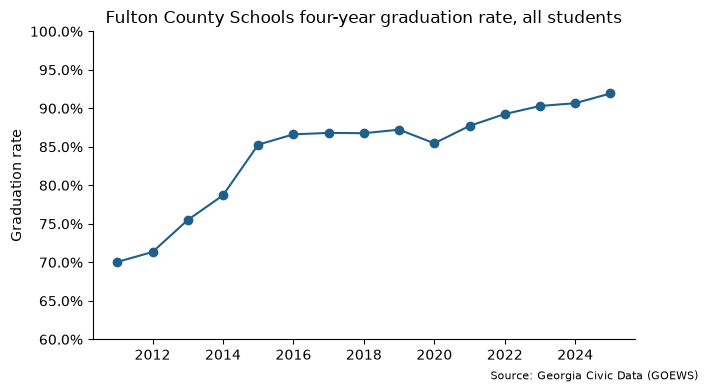

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

grads_all = grads[grads["demographic"] == "all"]

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(grads_all["year"], grads_all["graduation_rate"], marker="o", color="#1f5f8b")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0.6, 1)
ax.set_title("Fulton County Schools four-year graduation rate, all students")
ax.set_ylabel("Graduation rate")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.99, 0.01, "Source: Georgia Civic Data (GOEWS)", ha="right", fontsize=8)
plt.show()

### pandas or Polars

pandas is the default. Every table function takes `backend="polars"`, and
`gcd.set_option("backend", "polars")` switches the whole session:

In [7]:
gcd.rows(
    "graduation_rate_4_year_cohort",
    district="Fulton County",
    detail="districts",
    demographic="all",
    year=range(2023, 2026),
    quiet=True,
    backend="polars",
)

year,district_code,district_name,district_census_id,district_type,demographic,demographic_label,demographic_category,num_graduates,num_cohort,graduation_rate
i64,str,str,str,str,str,str,str,i64,i64,f64
2023,"""660""","""Fulton County""","""02280""","""standard""","""all""","""All""","""aggregate""",6815,7547,0.903
2024,"""660""","""Fulton County""","""02280""","""standard""","""all""","""All""","""aggregate""",6977,7695,0.9067
2025,"""660""","""Fulton County""","""02280""","""standard""","""all""","""All""","""aggregate""",7294,7934,0.9193


## Lookup tables

Datasets hold codes and figures, with place names added. Everything else
known about a place lives in shared lookup tables, called dimensions: a
district's type, a school's level, grade span, locale (city, suburb, town or
rural), charter status, address and coordinates, and a Census tract's land
area and population. `gcd.dimension()` returns one as a data frame, with the
same name filters as `gcd.rows()`.

Lookup tables help you:

- Browse what exists before you request data, such as every active high
  school in a district.
- Add attributes the datasets don't carry, then filter or group by them.
- Map schools with their coordinates.

Here are the first five active high schools in Fulton County with their
locale:

In [8]:
gcd.dimension(
    "schools",
    district="Fulton County",
    school_level="high",
    active=True,
    columns=["district_code", "school_code", "school_name", "locale"],
).head()

,district_code,school_code,school_name,locale
0,660,0106,Milton High School,suburb
1,660,0118,Hapeville Charter Career Academy,suburb
2,660,0119,Cambridge High School,suburb
3,660,0176,Banneker High School,suburb
4,660,0191,Roswell High School,city


To compare graduation rates by locale, merge the locale into school-level
graduation rates. School codes repeat across districts, so merge on
`district_code` and `school_code` together.

In [9]:
schools = gcd.dimension(
    "schools",
    district="Fulton County",
    columns=["district_code", "school_code", "locale"],
)

school_grads = gcd.rows(
    "graduation_rate_4_year_cohort",
    district="Fulton County",
    detail="schools",
    demographic="all",
    year=2025,
    quiet=True,
)

school_grads = school_grads.merge(schools, on=["district_code", "school_code"])
school_grads.groupby("locale")["graduation_rate"].median()

locale
city      0.95080
rural     0.94330
suburb    0.96585
Name: graduation_rate, dtype: float64

Fulton County has only two rural high schools, so treat this as an
illustration, not a finding.

## School zones and places

`gcd.school_zones()` returns school attendance zones as a geopandas
`GeoDataFrame`, ready to map. This map shows the high school zones in
Atlanta Public Schools:

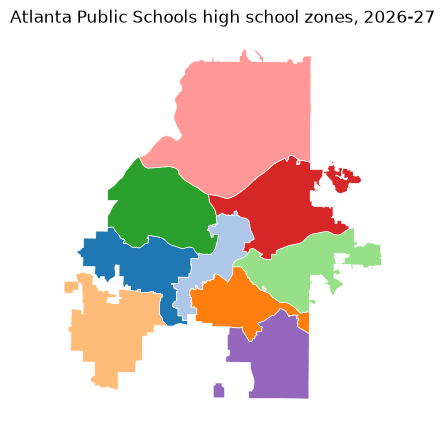

In [10]:
zones = gcd.school_zones(district="Atlanta Public Schools", zone_level="high")

ax = zones.plot(
    column="school_name", edgecolor="white", linewidth=0.5, figsize=(6, 5), cmap="tab20"
)
ax.set_title("Atlanta Public Schools high school zones, 2026-27")
ax.set_axis_off()
plt.show()

`gcd.locate()` goes the other way: give it an address or a point, and it
returns the places that contain it, including the county, Census tract,
school district and zoned schools. Addresses are geocoded on your computer
with the U.S. Census geocoder, so only the point reaches the Georgia Civic
Data API.

In [11]:
# The Georgia State Capitol
capitol = gcd.locate(address="206 Washington St SW, Atlanta, GA 30334")
capitol[["geographic_type", "geographic_id", "geographic_name", "grades"]].head()

GCDAdvisory: A zone is the default assignment, not the only option: a Georgia student may attend another public school by transfer, or a charter, magnet or other choice school. See attendance_rules for the main ways.


,geographic_type,geographic_id,geographic_name,grades
0,county,13121,Fulton,<NA>
1,tract,13121003500,Census Tract 35,<NA>
2,block_group,131210035001,"Block Group 1, Census Tract 35, Fulton Co...",<NA>
3,school_district,761,Atlanta Public Schools,<NA>
4,elementary_school,761-0199,Centennial Academy (Charter),K-5


The first five rows are shown; the rest are the zoned middle and high
schools.

## Data license and citation

The data is published under the [Creative Commons Attribution 4.0
International license (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/):
credit Georgia Civic Data and the original source. `gcd.citation()` writes
the citation for any result:

In [12]:
gcd.citation(grads)

"Four-Year Cohort Graduation Rate. Georgia Civic Data (georgiacivicdata.org), CC BY 4.0. https://georgiacivicdata.org/api/v1/datasets/graduation_rate_4_year_cohort. Original source: Governor's Office of Education and Workforce Strategy (GOEWS, formerly GOSA)."

The package code is MIT-licensed.

## Learn more

- [Get started](articles/get-started.ipynb): the catalog, names and filters,
  and the rules of the data that are easy to get wrong.
- [Analyzing Georgia data](articles/analysis.ipynb): joining two datasets
  and pooling rates from their counts.
- [School zones and places](articles/school-zones.ipynb): maps, zone status
  and locating points and addresses.
- [Reference](reference.md): every function.
- Georgia Civic Data: <https://georgiacivicdata.org>
- API documentation: <https://georgiacivicdata.org/docs>

```{toctree}
:hidden:
:maxdepth: 2

articles/get-started
reference
articles/index
agents
news
```